<div >
<img src = "../banner.jpg" />
</div>

<a target="_blank" href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture15/01_PCA_Text_as_Data.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Texto como Datos: Ejemplos

## Regresión con Texto: Gentzkow and Shapiro

Vamos a usar los datos del estudio de Gentzkow y Shapiro [2010], que analiza cómo los periódicos ajustan su contenido según la orientación política de sus lectores.


<div >
<img src = "figures/gentzgow_shapiro.png" />
</div>

Cargamos los paquetes

In [26]:
require("pacman")
p_load("tidyverse","textir","wordcloud")

El conjunto de datos resume el primer año del 109º Congreso de los Estados Unidos (2005) e incluye todos los discursos de ese año de los miembros de la Cámara de Representantes y del Senado.

El texto ya está tokenizado en *bigrams* , después de eliminar las *stopwords* y aplicar un algoritmo de lematización (usando el *Porter stemmer*).

In [27]:
data("congress109", package = "textir")

La matriz `congress109Counts` contiene el número de veces que cada una de las 1000 frases más comunes fue utilizada en el 109º Congreso por cada uno de los 529 miembros del Congreso (Cámara y Senado). 

Es decir, cada documento corresponde a la transcripción combinada de todos los discursos de un solo orador.

Podemos inspeccionar los conteos de algunas frases específicas para dos oradores:

In [28]:
congress109Counts[c("Barack Obama","John Boehner"),995:999]

2 x 5 sparse Matrix of class "dgCMatrix"
             stem.cel natural.ga hurricane.katrina trade.agreement
Barack Obama        .          1                20               7
John Boehner        .          .                14               .
             appropriation.bil
Barack Obama                12
John Boehner                 .

Tambien tenemos información sobre  el partido que pertenecen el estado, la camara, y la proporcion de votos que obtuvo Bush en la eleccion presindecial en el distrito/estado de cada representante

In [29]:
congress109Ideology[c("Barack Obama","John Boehner"),1:5]

,name,party,state,chamber,repshare
,<chr>,<fct>,<fct>,<fct>,<dbl>
Barack Obama,Barack Obama,D,IL,S,0.4479136
John Boehner,John Boehner,R,OH,H,0.6456248


Vamos a tratar de predecir estos votos  a partir de como los congresistas hablan. La idea es que el lenguage apela a los votantes: 

In [30]:
as.matrix(congress109Counts[c("Tom Price","William Jefferson"),c("death.tax","estate.tax")])

,death.tax,estate.tax
Tom Price,28,0
William Jefferson,2,32


### Regresión LASSO

En una primera etapa, los autores buscan predecir la ideología del distrito a partir del lenguaje del congresista. Definen con $i = 1, \dots, n$ con $n = 529$ congresistas y $j = 1, \dots, p$ con $p = 1{,}000$ frases.




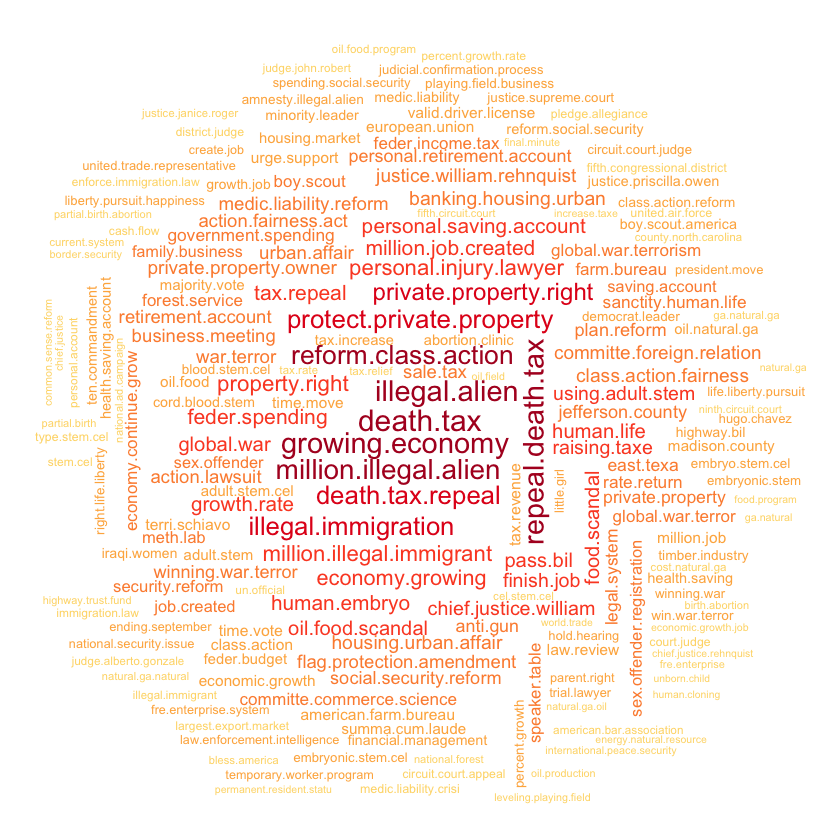

In [31]:
# Outcome
repshare <- congress109Ideology$repshare

# Veces que 
X1 <- as.matrix(congress109Counts)
words<-colnames(X1)

covariance<-apply(X1,2,function(x) cor(x,repshare))

                  

wordcloud(words = words,
          freq = covariance,
          min.freq = 0,
          scale = c(1.5, 0.1), 
          max.words=200, 
          random.order=FALSE, 
          colors=brewer.pal(8, "YlOrRd"))
          

Sin embargo, para ilustrar haremos la regresión sobre si utilizó la frase, ignorando el número de veces. Entonces definimos el indicador de uso de la frase $j$ por el congresista $i$ como:

$$D_{ij} = \mathbf{1}\{c_{ij} > 0\} \in \{0, 1\}$$

donde $c_{ij}$ es el número de veces que el congresista $i$ usó la frase $j$.


El modelo es:

$$\text{RepShare}_i = \alpha + \sum_{j=1}^{p} \beta_j D_{ij} + u_i$$

Como $p > n$, MCO no esta identificado y lo estimamos por LASSO:

$$(\hat{\alpha}, \hat{\boldsymbol{\beta}}) = \underset{\alpha,\, \boldsymbol{\beta}}{\arg\min}
\; \frac{1}{n} \sum_{i=1}^{n} \left(\text{RepShare}_i - \alpha - \sum_{j=1}^{p} \beta_j D_{ij}\right)^2
+ \lambda \sum_{j=1}^{p} |\beta_j|$$

con $\lambda$ seleccionado por validación cruzada. La penalización lleva a cero los coeficientes
de las frases sin poder predictivo, dejando solo las frases cuyo uso discrimina entre distritos
republicanos y demócratas.

In [32]:
# Predictores
X <- as(congress109Counts, "dMatrix")

La función `as(congress109Counts, "dMatrix")` convierte la matriz de conteos a formato de matriz dispersa (*sparse matrix*), que almacena únicamente los valores distintos de cero. Esto es esencial aquí porque la matriz de 529 congresistas × 1,000 frases está dominada por ceros (la mayoría de los congresistas no usan la mayoría de las frases).

Para estimar, vamos a usar `cv.gamlr` del paquete `gamlr`. Esto equivale a usar `train()` de `caret` con `method = "glmnet"` y validación cruzada. Estima el LASSO sobre un camino de valores de $\lambda$ y selecciona el óptimo automáticamente.

El argumento `X>0` binariza la matriz de conteos en el momento de la llamada, de modo que los regresores son indicadores de uso de cada frase, no los conteos crudos.

In [33]:
# lasso
lassoslant <- cv.gamlr(X>0, repshare)  

'as(<lgCMatrix>, "dgCMatrix")' is deprecated.
Use 'as(., "dMatrix")' instead.
See help("Deprecated") and help("Matrix-deprecated").



Extraemos los coeficientes del modelo LASSO excepto el intercepto (la primera fila es el intercepto, así que [-1,])

In [34]:
B <- coef(lassoslant, select = "min")[-1,]

In [35]:
top_rep <- tail(sort(round(B[B != 0], 4)), 10)

data.frame(
  Frase       = names(top_rep),
  Coeficiente = as.numeric(top_rep)
)

Frase,Coeficiente
<chr>,<dbl>
global.war,0.0112
raise.taxe,0.0117
pass.bil,0.0118
look.forward,0.0132
illegal.immigration,0.0144
private.property,0.0165
action.lawsuit,0.0175
troop.famili,0.0197
million.illegal.alien,0.0299


In [36]:
top_dem <- head(sort(round(B[B != 0], 4)), 10)

data.frame(
  Frase       = names(top_dem),
  Coeficiente = as.numeric(top_dem)
)

Frase,Coeficiente
<chr>,<dbl>
congressional.black.caucu,-0.0829
issue.facing.american,-0.0530
family.value,-0.0461
universal.health.care,-0.0410
minority.owned.business,-0.0335
civil.right,-0.0298
voter.registration,-0.0286
strong.opposition,-0.0259
congressional.hispanic.caucu,-0.0241
